# Drift-canceling A-LQR ablation

Compare the current A-LQR push with orthogonal drift cancellation, using the same Identity, Mean Jacobian, and Random dynamics and sparse actuation settings as notebook 02:

$$u_\ell = \alpha_\ell K_\ell v_\ell - w K_\ell d_{\perp,\ell},\qquad
\alpha_\ell=\lambda\|E_\ell\|-v_\ell^\top x_\ell,$$
$$d_\ell=x_\ell-x_\ell^{\mathrm{nominal}},\qquad
d_{\perp,\ell}=d_\ell-(v_\ell^\top d_\ell)v_\ell.$$

The independent, identical nominal model consumes **the same generated tokens**, not independently generated stories. `w=0` is the original controller; `w=1` adds cancellation. A full-sequence replay can differ slightly from cached generation in BF16, so replay metrics are approximate. Controller drift logs measure block **inputs**; `completion_metrics()['orthogonal']` measures the final **pre-norm output**, not those logs.

The controller checks have already passed; this notebook now goes directly from loading E/A to the sweep. Experiment size is controlled by `PILOT`, `TRIALS`, `LAMBDAS`, `EVERY`, and `DRIFT_WEIGHTS` below. E/A caches are shared with notebook 02; results go to a separate drift directory, split by pilot/full and Q/R/QF.


In [1]:
from pathlib import Path
import gc, importlib, random, sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'llm' / 'steering.py').is_file())
sys.path.insert(0, str(REPO_ROOT))
import llm.model, llm.concepts, llm.jacobian, llm.steering, llm.trace, llm.judge
for module in (llm.model, llm.concepts, llm.jacobian, llm.steering, llm.trace, llm.judge):
    importlib.reload(module)
from llm.model import load_model, blocks
from llm.concepts import concept_direction, load_concept_prompts
from llm.jacobian import efficient_mean_jacobian
from llm.steering import DriftLQRSteering, sample
from llm.trace import trace, completion_metrics
from llm.judge import build_judge, concept_criterion, COHERENCE, repetition

MODEL_NAME = 'Qwen/Qwen3-4B'
# MODEL_NAME = 'Qwen/Qwen3-0.6B'
# MODEL_NAME = 'roneneldan/TinyStories-28M'
CONCEPT = 'football'
PROMPT = 'Once upon a time'
SEED = 0
DIRECTION_SAMPLES = 200
JACOBIAN_SAMPLES = 50
MAX_CTX = 32
BATCH_SIZE = 8
RANDOM_SEED = 0

Q, R, QF = 0.1, 10, 0.1
STEER_LAST_N_LAYERS = None
EVERY = (1, 2, 3)
DRIFT_WEIGHTS = (0.0, 1.0, 2.0)
PILOT = False
TRIALS = 20 if PILOT else 100
LAMBDAS = (2, 4) if PILOT else (1, 2, 3, 4, 5, 6, 7, 8)
MAX_NEW_TOKENS = 96
TEMPERATURE, TOP_P = 0.7, 0.95

/home/dunstan/git/kae-steering/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
random.seed(SEED)
torch.manual_seed(SEED)
tokenizer, model = load_model(MODEL_NAME)
nominal = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=next(model.parameters()).dtype,
    device_map=str(model.device),
    attn_implementation=model.config._attn_implementation,
).eval()
NUM_LAYERS = len(blocks(model))
HIDDEN = model.get_input_embeddings().weight.shape[1]
PROMPT_LEN = len(tokenizer(PROMPT)['input_ids'])
ARTIFACTS = REPO_ROOT / 'artifacts' / MODEL_NAME.rsplit('/', 1)[-1].lower()
ARTIFACTS.mkdir(parents=True, exist_ok=True)
RUN_DIR = ARTIFACTS / 'drift_lqr' / ('pilot' if PILOT else 'full') / f'q{Q:g}_r{R:g}_qf{QF:g}'
RUN_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_KWARGS = dict(max_new_tokens=MAX_NEW_TOKENS, temperature=TEMPERATURE, top_p=TOP_P)
print(f'{MODEL_NAME}: {NUM_LAYERS} blocks, hidden {HIDDEN}, {next(model.parameters()).dtype}')
print('Nominal:', nominal.device, next(nominal.parameters()).dtype, nominal.config._attn_implementation)
print('Results:', RUN_DIR)


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 592.86it/s]


Qwen/Qwen3-4B: 36 blocks, hidden 2560, torch.bfloat16
Nominal: cuda:0 torch.bfloat16 sdpa
Results: /home/dunstan/git/kae-steering/artifacts/qwen3-4b/drift_lqr/full/q0.1_r10_qf0.1


In [3]:
E_PATH = ARTIFACTS / f'E_{CONCEPT}_n{DIRECTION_SAMPLES}_seed{SEED}.pt'
if E_PATH.exists():
    E = torch.load(E_PATH, weights_only=True)
else:
    random.seed(SEED)
    E = concept_direction(model, tokenizer, CONCEPT, DIRECTION_SAMPLES, BATCH_SIZE)
    torch.save(E, E_PATH)
print('E:', tuple(E.shape))

E: (37, 2560)


In [4]:
A_PATH = ARTIFACTS / f'A_{CONCEPT}_n{JACOBIAN_SAMPLES}_ctx{MAX_CTX}_seed{SEED}.pt'
if A_PATH.exists():
    A_jac = torch.load(A_PATH, weights_only=True)
else:
    random.seed(SEED + 1)
    targets, _ = load_concept_prompts(CONCEPT, JACOBIAN_SAMPLES)
    A_jac = efficient_mean_jacobian(model, tokenizer, targets, max_ctx=MAX_CTX)
    torch.save(A_jac, A_PATH)

B_random = torch.randn(NUM_LAYERS, HIDDEN, HIDDEN, generator=torch.Generator().manual_seed(RANDOM_SEED))
size = torch.linalg.matrix_norm(A_jac - torch.eye(HIDDEN)) / torch.linalg.matrix_norm(B_random)
A_random = torch.eye(HIDDEN) + size[:, None, None] * B_random
del B_random

OPERATORS = {'Identity': torch.eye(HIDDEN).expand(NUM_LAYERS, -1, -1), 'Mean Jacobian': A_jac, 'Random': A_random}
print('Mean Jacobian:', A_PATH.name)

Mean Jacobian: A_football_n50_ctx32_seed0.pt


## Sweep

One controller per (operator, every) is reused across weights and then lambdas. Each weight/operator/sparsity uses matching seeds for a given lambda. The progress bar counts completion batches. The unsteered baseline is sampled separately without a controller and is labeled `every=0`, `drift_weight=0`; replay-only metrics are left missing for it, as in notebook 02.

`along_v`, `change`, `orthogonal`, and `push_energy` are consumed immediately after each replay, before the controller changes. Unjudged completions are saved before loading Granite.


In [5]:
torch.manual_seed(SEED)
ids = sample(model, tokenizer, PROMPT, TRIALS, **SAMPLE_KWARGS)
results = [{'every': 0, 'operator': 'Unsteered', 'drift_weight': 0.0, 'lambda': 0.0,
            'completion': text.strip()}
           for text in tokenizer.batch_decode(ids[:, PROMPT_LEN:], skip_special_tokens=True)]
del ids

sweep_batches = len(EVERY) * len(OPERATORS) * len(DRIFT_WEIGHTS) * len(LAMBDAS)
with tqdm(total=sweep_batches, desc='Drift A-LQR sweep', unit='batch') as progress:
    for every in EVERY:
        for name, A in OPERATORS.items():
            controller = DriftLQRSteering(model, nominal, A, E, Q, R, QF,
                                          steer_last_n_layers=STEER_LAST_N_LAYERS, every=every)
            for weight in DRIFT_WEIGHTS:
                controller.drift_weight = weight
                for i, lmbda in enumerate(LAMBDAS):
                    torch.manual_seed(SEED + i)
                    ids = sample(model, tokenizer, PROMPT, TRIALS,
                                 controller=controller, lmbda=lmbda, **SAMPLE_KWARGS)
                    tr = trace(model, controller, lmbda, ids, PROMPT_LEN)
                    batch_metrics = completion_metrics(tr)
                    del tr
                    texts = tokenizer.batch_decode(ids[:, PROMPT_LEN:], skip_special_tokens=True)
                    for text, metrics in zip(texts, batch_metrics):
                        results.append({'every': every, 'operator': name, 'drift_weight': weight,
                                        'lambda': lmbda, **metrics, 'completion': text.strip()})
                    progress.set_postfix(every=every, operator=name, weight=weight, lmbda=lmbda)
                    progress.update(1)
                    del ids, batch_metrics, texts
            del controller
            gc.collect()
            torch.cuda.empty_cache()

results = pd.DataFrame(results)
results.to_csv(RUN_DIR / f'drift_ablation_{CONCEPT}_unjudged.csv', index=False)


Drift A-LQR sweep: 100%|██████████| 216/216 [28:33<00:00,  7.93s/batch, every=3, lmbda=8, operator=Random, weight=2]       


## Fast judge

Free both language models before loading Granite Guardian. Its current fast yes/no API scores the concept and coherence separately with progress bars, deduplication, and length-sorted batches. `JUDGE_BATCH=128` matches the current notebook 02 setting; reduce it if GPU memory is limited. Judging can be rerun on the saved unjudged CSV without regenerating completions.


In [6]:
JUDGE_BATCH = 512

In [7]:
# All controllers and traces were released above; neither model remains referenced by them.
for name in ('model', 'nominal', 'judge'):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()
judge = build_judge(batch_size=JUDGE_BATCH)
results = pd.read_csv(RUN_DIR / f'drift_ablation_{CONCEPT}_unjudged.csv')
texts = results['completion'].tolist()
print(f'Judging {len(texts):,} completions ({len(set(texts)):,} unique), two criteria, batch size {JUDGE_BATCH}.')
results['concept'] = judge(concept_criterion(CONCEPT), PROMPT, texts, desc=f'Concept: {CONCEPT} (1/2)')
results['coherent'] = judge(COHERENCE, PROMPT, texts, desc='Coherence (2/2)')
results['both'] = results['concept'] & results['coherent']
results['repetition'] = results['completion'].map(repetition)
results.to_csv(RUN_DIR / f'drift_ablation_{CONCEPT}.csv', index=False)


Loading weights: 100%|██████████| 362/362 [00:01<00:00, 244.69it/s]


Judging 21,700 completions (21,351 unique), two criteria, batch size 512.


Coherence (2/2): 100%|██████████| 21351/21351 [23:54<00:00, 14.89response/s]


## Coherence versus concept rate

One figure per actuation interval; operator fixes the color and cancellation weight fixes the line style. Error bars on **both** axes are binomial standard errors $\sqrt{p(1-p)/n}$. Labels give lambda. The separately sampled unsteered baseline is a black star. These marginal error bars do not estimate uncertainty in paired differences.


In [8]:
groups = results.groupby(['every', 'operator', 'drift_weight', 'lambda'], sort=False)
summary = groups[['concept', 'coherent', 'both', 'repetition', 'along_v', 'change', 'orthogonal', 'push_energy']].mean()
summary['n'] = groups.size()
summary['concept_se'] = np.sqrt(summary['concept'] * (1 - summary['concept']) / summary['n'])
summary['coherent_se'] = np.sqrt(summary['coherent'] * (1 - summary['coherent']) / summary['n'])
summary.to_csv(RUN_DIR / f'drift_ablation_{CONCEPT}_summary.csv')
print(summary.round(3).to_string())

                                         concept  coherent  both  repetition  along_v  change  orthogonal  push_energy    n  concept_se  coherent_se
every operator      drift_weight lambda                                                                                                             
0     Unsteered     0.0          0.0        0.00      0.99  0.00       0.004      NaN     NaN         NaN          NaN  100       0.000        0.010
1     Identity      0.0          1.0        0.14      0.98  0.14       0.008  114.055   0.332       0.258        0.006  100       0.035        0.014
                                 2.0        0.46      0.97  0.45       0.004  172.961   0.527       0.425        0.012  100       0.050        0.017
                                 3.0        0.75      0.80  0.63       0.008  237.650   0.711       0.588        0.021  100       0.043        0.040
                                 4.0        0.97      0.76  0.74       0.006  263.710   0.819       0.698 

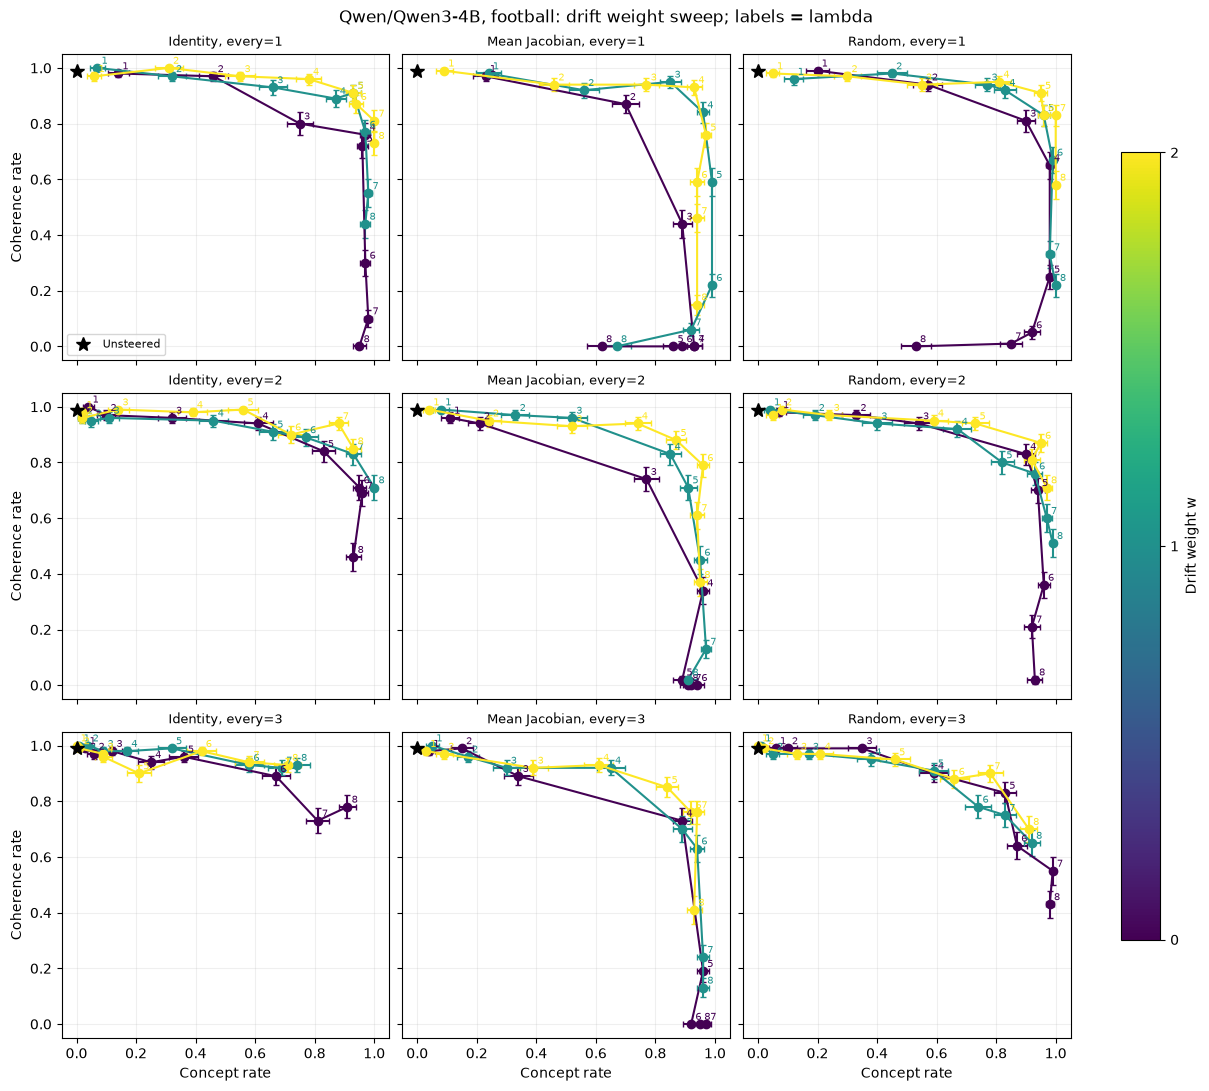

In [9]:
baseline = summary.loc[(0, 'Unsteered', 0.0, 0.0)]
weights = np.sort(
    summary.drop('Unsteered', level='operator')
    .index.get_level_values('drift_weight').unique()
)
cmap = plt.get_cmap('viridis')
norm = plt.Normalize(
    vmin=weights.min(),
    vmax=weights.max() if len(weights) > 1 else weights.min() + 1,
)

fig, axes = plt.subplots(
    len(EVERY), len(OPERATORS),
    figsize=(4 * len(OPERATORS), 3.6 * len(EVERY)),
    sharex=True, sharey=True, squeeze=False,
    layout='constrained',
)

for row, every in zip(axes, EVERY):
    for ax, name in zip(row, OPERATORS):
        block = summary.xs((every, name), level=['every', 'operator'])

        for weight, curve in block.groupby(level='drift_weight'):
            curve = curve.sort_index(level='lambda')
            color = cmap(norm(weight))

            ax.errorbar(
                curve['concept'], curve['coherent'],
                xerr=curve['concept_se'], yerr=curve['coherent_se'],
                marker='o', capsize=2, color=color,
            )
            for lmbda, point in zip(
                curve.index.get_level_values('lambda'), curve.itertuples()
            ):
                ax.annotate(
                    f'{lmbda:g}', (point.concept, point.coherent),
                    fontsize=7, color=color,
                    xytext=(3, 3), textcoords='offset points',
                )

        ax.plot(
            baseline['concept'], baseline['coherent'],
            'k*', ms=10, label='Unsteered', zorder=10,
        )
        ax.set_title(f'{name}, every={every}', fontsize=9)
        ax.grid(alpha=0.2)

axes[0, 0].set(xlim=(-0.05, 1.05), ylim=(-0.05, 1.05))
axes[0, 0].legend(fontsize=8)

for ax in axes[-1]:
    ax.set_xlabel('Concept rate')
for ax in axes[:, 0]:
    ax.set_ylabel('Coherence rate')

fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=axes.ravel().tolist(),
    label='Drift weight w',
    ticks=weights,
    shrink=0.8,
)
fig.suptitle(f'{MODEL_NAME}, {CONCEPT}: drift weight sweep; labels = lambda')
fig.savefig(RUN_DIR / f'drift_ablation_{CONCEPT}_grid.png', dpi=150)
plt.show()

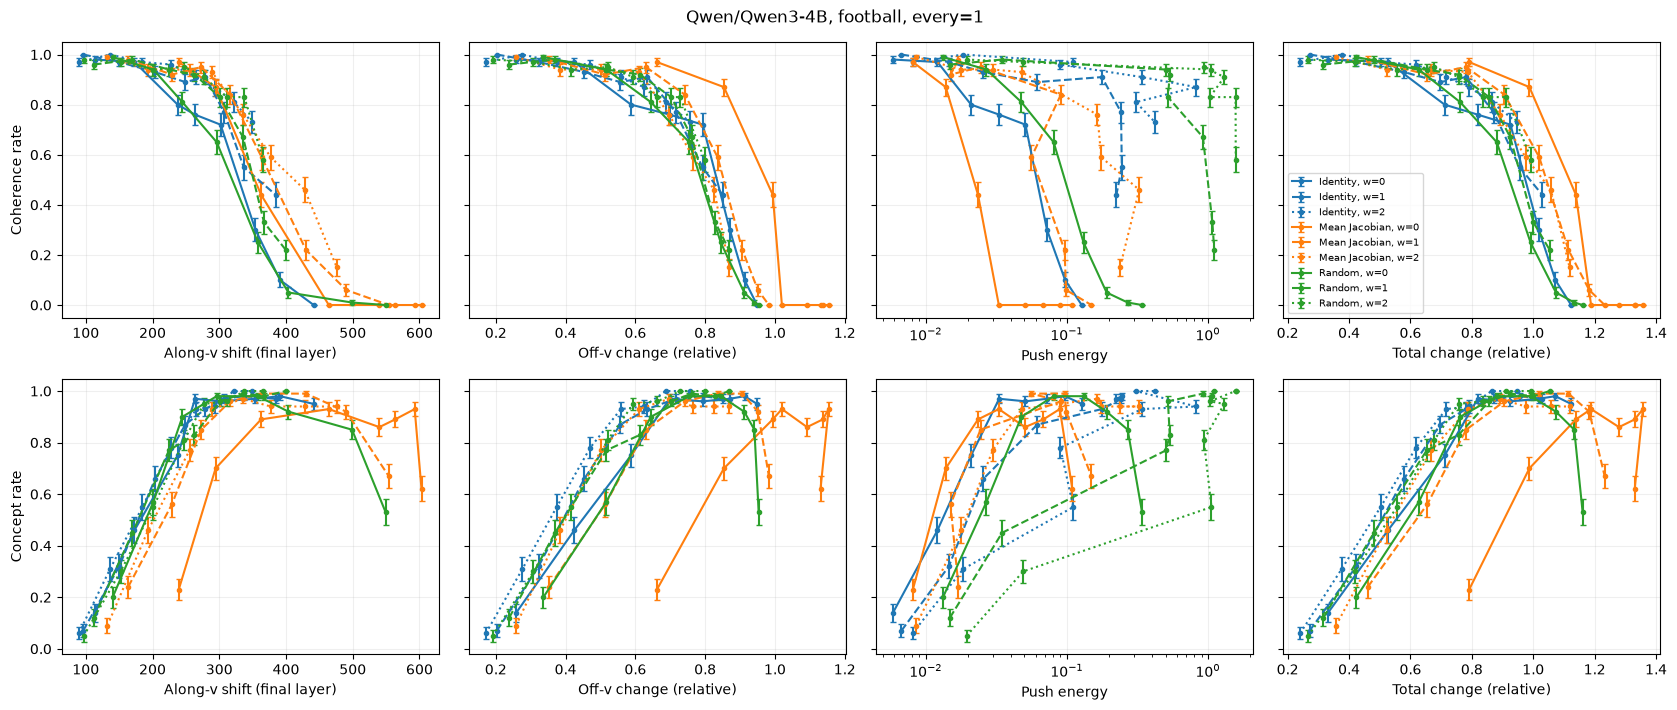

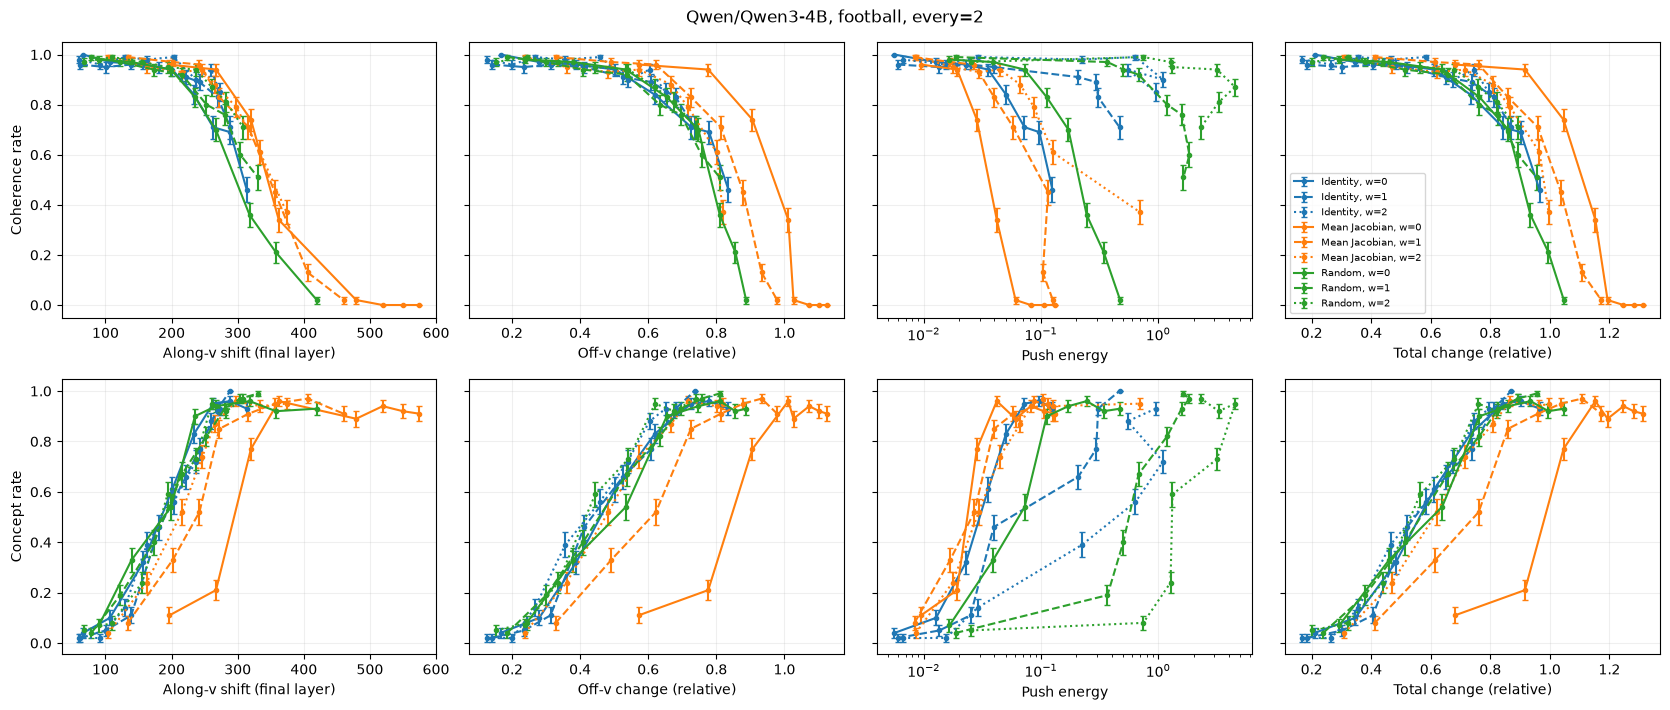

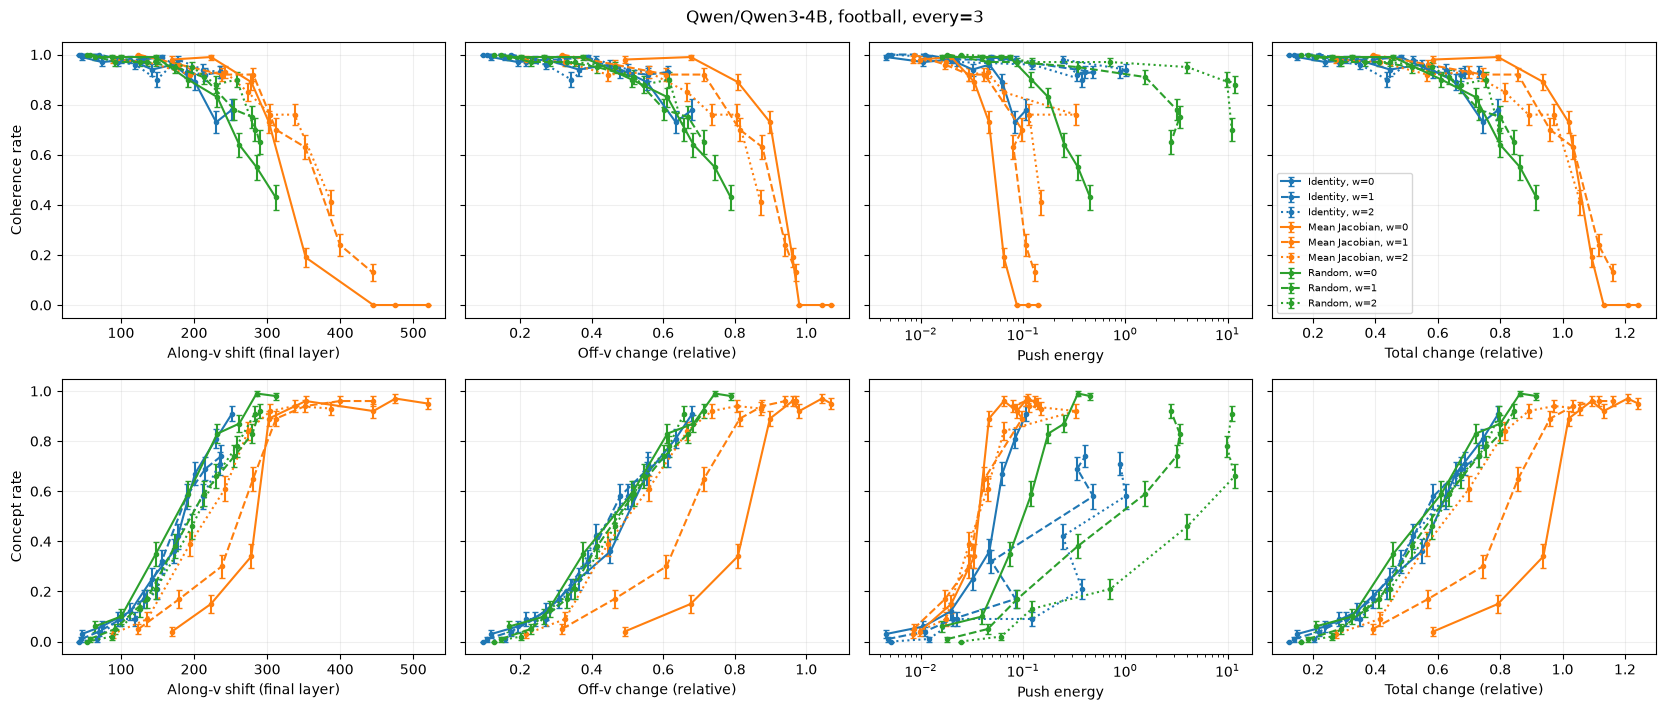

In [10]:
METRICS = {'along_v': 'Along-v shift (final layer)', 'orthogonal': 'Off-v change (relative)',
           'push_energy': 'Push energy', 'change': 'Total change (relative)'}
OUTCOMES = {'coherent': 'Coherence rate', 'concept': 'Concept rate'}
colors = dict(zip(OPERATORS, plt.get_cmap('tab10').colors))
styles = dict(zip(DRIFT_WEIGHTS, ('-', '--', ':', '-.')))
steered = summary.drop(index=0, level='every')

for every in EVERY:
    block = steered.xs(every, level='every')
    fig, axes = plt.subplots(len(OUTCOMES), len(METRICS), figsize=(4.2 * len(METRICS), 3.6 * len(OUTCOMES)),
                             sharey='row', squeeze=False)
    for (name, weight), curve in block.groupby(level=['operator', 'drift_weight'], sort=False):
        curve = curve.sort_index(level='lambda')
        for row, outcome in zip(axes, OUTCOMES):
            for ax, metric in zip(row, METRICS):
                ax.errorbar(curve[metric], curve[outcome], yerr=curve[f'{outcome}_se'], color=colors[name],
                            linestyle=styles[weight], marker='o', ms=3, capsize=2, label=f'{name}, w={weight:g}')
    for row, ylabel in zip(axes, OUTCOMES.values()):
        row[0].set_ylabel(ylabel)
        row[list(METRICS).index('push_energy')].set_xscale('log')
        for ax, xlabel in zip(row, METRICS.values()):
            ax.set_xlabel(xlabel)
            ax.grid(alpha=0.2)
    axes[0, -1].legend(fontsize=7)
    fig.suptitle(f'{MODEL_NAME}, {CONCEPT}, every={every}')
    fig.tight_layout()
    fig.savefig(RUN_DIR / f'drift_metrics_{CONCEPT}_every{every}.png', dpi=150)
    plt.show()

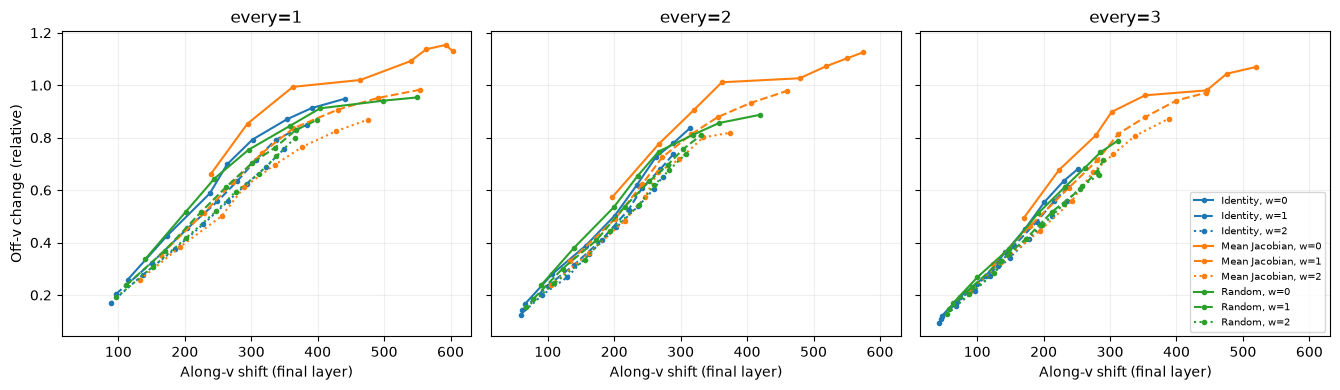

In [11]:
fig, axes = plt.subplots(1, len(EVERY), figsize=(4.5 * len(EVERY), 4), sharex=True, sharey=True, squeeze=False)
for ax, every in zip(axes[0], EVERY):
    for (name, weight), curve in steered.xs(every, level='every').groupby(level=['operator', 'drift_weight'], sort=False):
        curve = curve.sort_index(level='lambda')
        ax.plot(curve['along_v'], curve['orthogonal'], color=colors[name], linestyle=styles[weight],
                marker='o', ms=3, label=f'{name}, w={weight:g}')
    ax.set(title=f'every={every}', xlabel='Along-v shift (final layer)')
    ax.grid(alpha=0.2)
axes[0, 0].set_ylabel('Off-v change (relative)')
axes[0, -1].legend(fontsize=7)
fig.tight_layout()
fig.savefig(RUN_DIR / f'drift_aim_{CONCEPT}.png', dpi=150)
plt.show()

In [12]:
import statsmodels.formula.api as smf
from scipy.stats import chi2

df = results[results['every'] != 0].dropna(subset=['along_v', 'orthogonal', 'push_energy']).copy()
df['coherent'] = df['coherent'].astype(int)
df['log_orth'], df['log_energy'] = np.log(df['orthogonal']), np.log(df['push_energy'])
base = 'coherent ~ scale(along_v) + scale(log_orth) + scale(log_energy)'
fit = smf.logit(base, df).fit(disp=0)
print(fit.summary2().tables[1].round(3))
for extra in ('C(drift_weight)', 'C(operator) + C(every)'):
    full = smf.logit(f'{base} + {extra}', df).fit(disp=0)
    lr = 2 * (full.llf - fit.llf)
    print(f'{extra} beyond the three metrics: LR {lr:.1f}, p = {chi2.sf(lr, full.df_model - fit.df_model):.3g}')

                   Coef.  Std.Err.       z  P>|z|  [0.025  0.975]
Intercept          2.156     0.040  53.578    0.0   2.077   2.234
scale(along_v)    -1.707     0.052 -32.815    0.0  -1.809  -1.605
scale(log_orth)   -0.969     0.076 -12.704    0.0  -1.119  -0.820
scale(log_energy) -0.193     0.023  -8.560    0.0  -0.237  -0.149
C(drift_weight) beyond the three metrics: LR 429.0, p = 7.09e-94
C(operator) + C(every) beyond the three metrics: LR 118.2, p = 1.32e-24
